# E242 · Constraining reconstruction loss and RankMe

**Strict loss constraints mostly selected Skip.** At +16, the rank-first rule selected Skip
on 28 of 32 paired selections. None of its selected actions worsened either reconstruction
loss on the opposite draw. Mean new-bank RankMe rose about 0.003, and the semantic
estimate was −0.12 pp versus Skip. The selection remains a retrospective cross-draw
diagnostic on one archived learner seed.

## Design

Reuse existing branch receipts for 36 development captures and 16 capture-disjoint
test captures from the Windows E242 holdout. The test captures come from MAE seed
2026. Select by one augmentation mask draw and score the chosen branch on the other,
in both directions. The archived direct advantage and hybrid-direct choices used only
pre-action features and are scored on both draws. The hybrid's direct head in this
archive targets an objective change from the shared pre-action state.

**Rank first** maximizes the change in new-bank RankMe among actions whose new and
historical reconstruction losses both stay within the tolerance. **Loss first** minimizes
the mean relative change across those losses, subject to a floor on new-bank RankMe.
Both start with zero tolerance relative to the shared pre-action checkpoint. The sweep
loosens the reconstruction tolerance to 0.25% and 0.50%, and lets the rank floor fall
0.50% and 1.00%. Positive relative loss means deterioration.

The strongest fixed action under each rule is chosen only from development means.
The strongest semantic fixed action is 50% replay at +1 and Skip at +16. The strongest
**active** fixed action by development semantics is 50% replay at +1 and incoming
0.125× at +16. Weighted O3 uses the archived O3-style bank objective built from new-bank
loss and RankMe. Its retrospective action selection also crosses the paired mask draws.

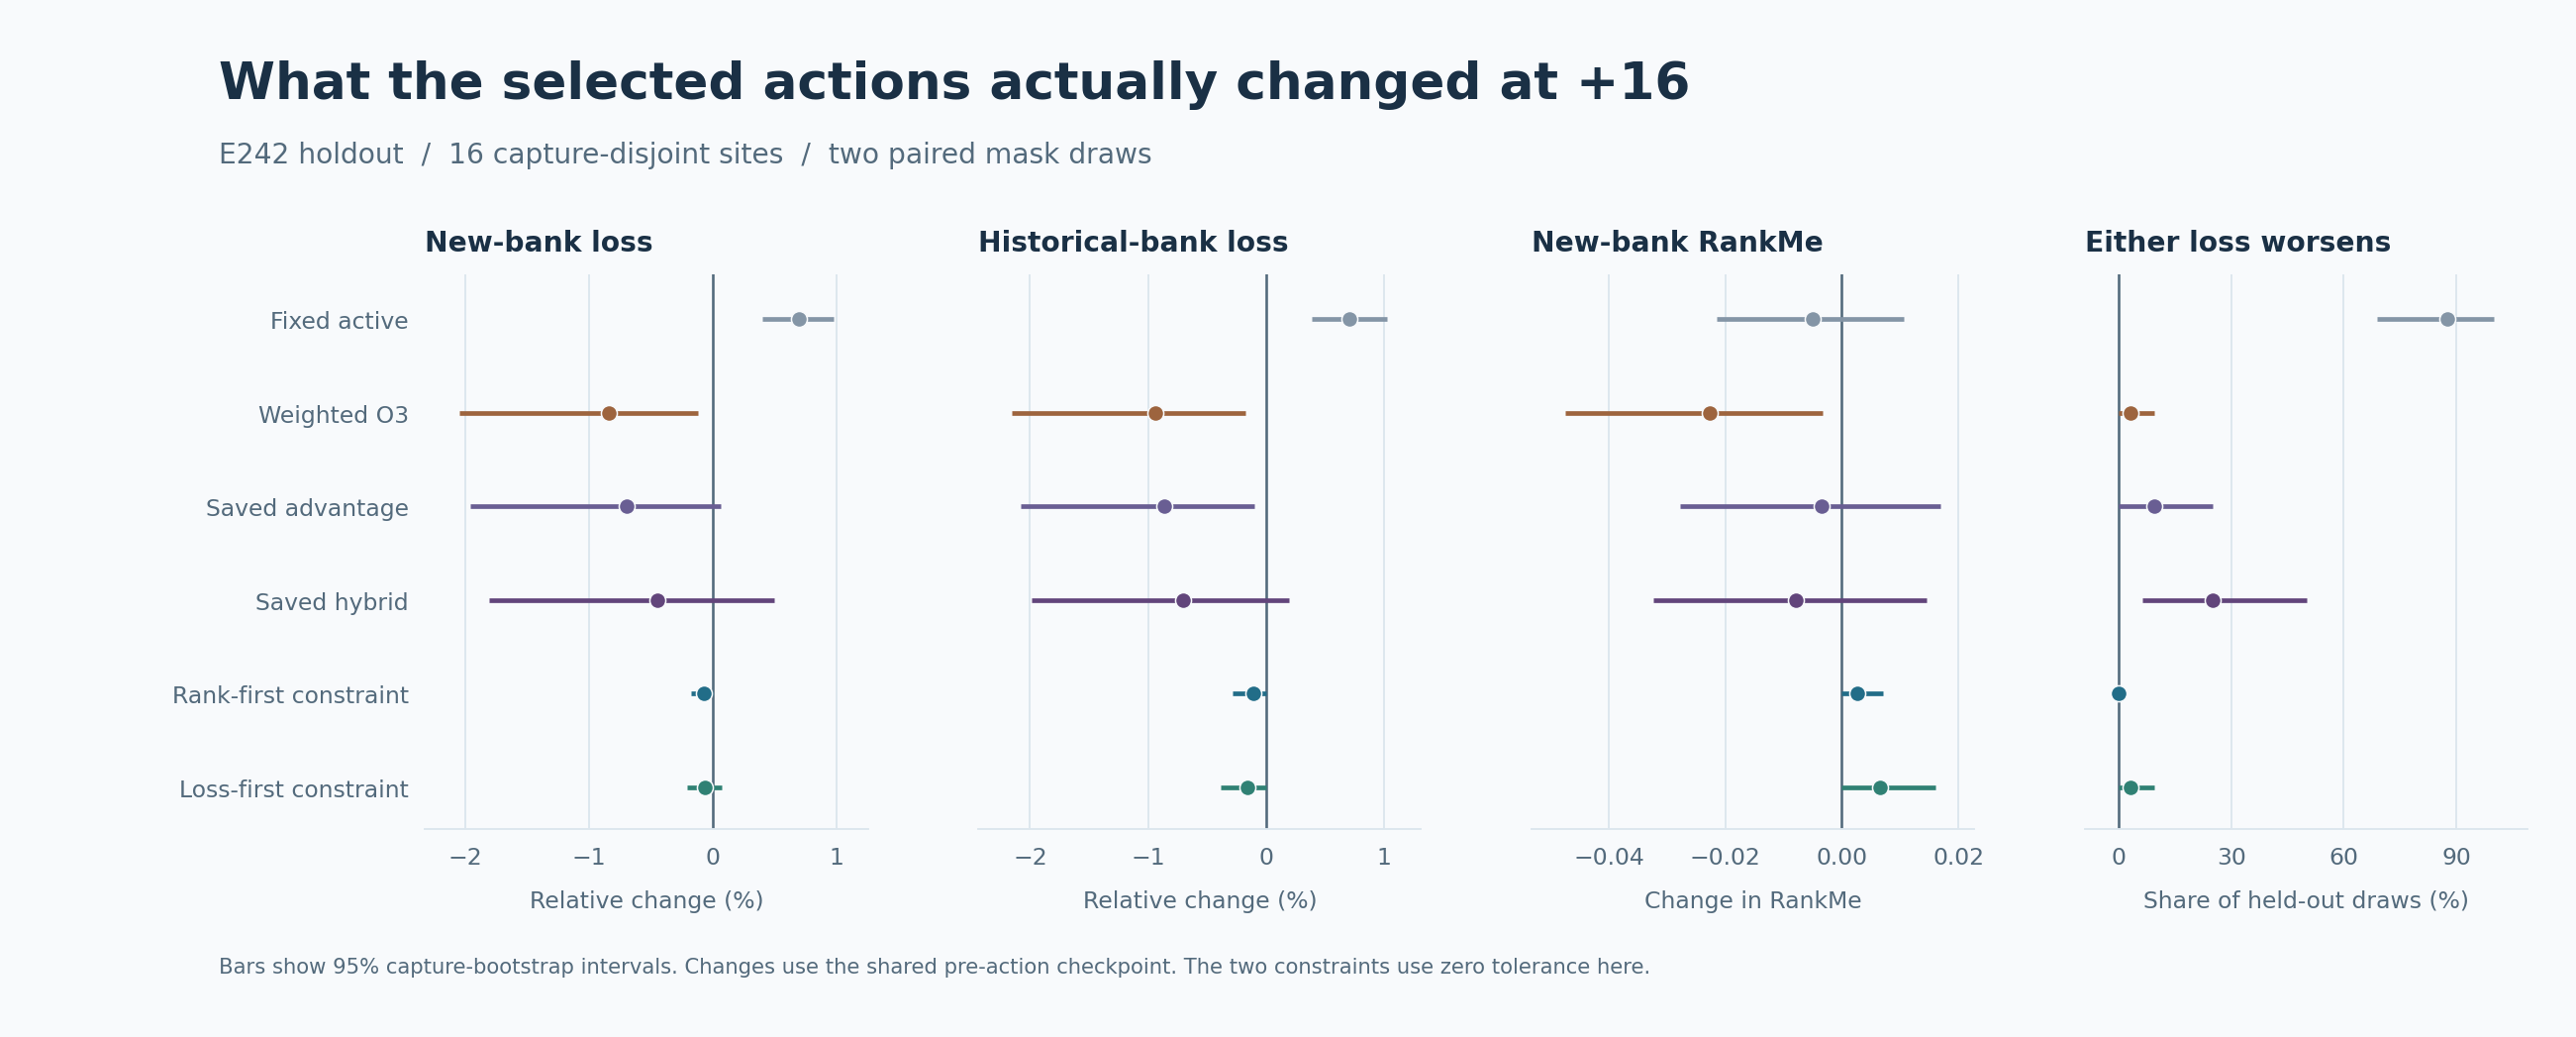

## Measured endpoint changes

| Horizon | Policy | New loss (%) | Historical loss (%) | New RankMe | Historical RankMe | Semantic (pp) | Either loss worsens |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| +1 | Strongest fixed non-Skip | +0.208 [+0.125, +0.293] | +0.176 [+0.095, +0.257] | -0.003 [-0.008, +0.001] | -0.004 [-0.007, +0.000] | -0.102 [-0.216, +0.022] | 90.6% |
| +1 | Cross-draw weighted O3 | -0.007 [-0.022, +0.001] | -0.011 [-0.035, +0.002] | +0.000 [-0.002, +0.001] | -0.001 [-0.002, +0.000] | -0.015 [-0.039, +0.000] | 3.1% |
| +1 | Saved direct advantage | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | 0.0% |
| +1 | Saved hybrid direct | +0.038 [-0.013, +0.105] | +0.018 [-0.023, +0.070] | +0.000 [-0.002, +0.001] | -0.001 [-0.003, +0.001] | -0.017 [-0.054, +0.010] | 25.0% |
| +1 | Rank-first constrained | +0.000 [+0.000, +0.001] | +0.001 [+0.000, +0.002] | +0.000 [+0.000, +0.001] | +0.000 [+0.000, +0.000] | -0.005 [-0.015, +0.000] | 3.1% |
| +1 | Loss-first constrained | +0.000 [+0.000, +0.001] | +0.001 [+0.000, +0.002] | +0.000 [+0.000, +0.001] | +0.000 [+0.000, +0.000] | -0.005 [-0.015, +0.000] | 3.1% |
| +16 | Strongest fixed non-Skip | +0.693 [+0.400, +0.977] | +0.707 [+0.388, +1.028] | -0.005 [-0.022, +0.011] | +0.000 [-0.013, +0.013] | +0.109 [-0.195, +0.413] | 87.5% |
| +16 | Cross-draw weighted O3 | -0.839 [-2.049, -0.117] | -0.939 [-2.152, -0.174] | -0.023 [-0.047, -0.003] | -0.015 [-0.042, +0.007] | +0.007 [-0.320, +0.324] | 3.1% |
| +16 | Saved direct advantage | -0.699 [-1.956, +0.065] | -0.867 [-2.076, -0.098] | -0.004 [-0.028, +0.017] | -0.005 [-0.030, +0.016] | +0.101 [-0.252, +0.436] | 9.4% |
| +16 | Saved hybrid direct | -0.449 [-1.808, +0.492] | -0.700 [-1.991, +0.193] | -0.008 [-0.032, +0.015] | -0.019 [-0.055, +0.010] | +0.216 [-0.164, +0.572] | 25.0% |
| +16 | Rank-first constrained | -0.071 [-0.174, +0.000] | -0.111 [-0.286, +0.000] | +0.003 [+0.000, +0.007] | +0.006 [+0.000, +0.017] | -0.123 [-0.349, +0.000] | 0.0% |
| +16 | Loss-first constrained | -0.061 [-0.208, +0.068] | -0.155 [-0.381, +0.000] | +0.007 [+0.000, +0.016] | +0.008 [-0.001, +0.021] | -0.103 [-0.362, +0.077] | 3.1% |

Brackets are 95% bootstrap intervals over held-out captures. Mask draws stay together. The interval for a policy with zero observed violations is degenerate in this sample.

## Threshold sweep

| Horizon | Rule | Tolerance | Strongest fixed under rule | Non-Skip choices | Chosen violation rate | Regret reduction vs fixed | Paired draws |
| --- | --- | ---: | --- | ---: | ---: | ---: | ---: |
| +1 | rank-first | 0.00% | A0 skip | 1/32 | 3.1% | +0.000 [+0.000, +0.000] | 31 |
| +1 | rank-first | 0.25% | A0 skip | 14/32 | 0.0% | +0.002 [+0.000, +0.004] | 32 |
| +1 | rank-first | 0.50% | A0 skip | 15/32 | 6.2% | +0.004 [+0.001, +0.007] | 30 |
| +1 | loss-first | 0.00% | A0 skip | 1/32 | 0.0% | +0.000 [-0.001, +0.000] | 32 |
| +1 | loss-first | 0.50% | A0 skip | 4/32 | 0.0% | +0.012 [-0.001, +0.037] | 32 |
| +1 | loss-first | 1.00% | A0 skip | 4/32 | 0.0% | +0.012 [-0.001, +0.037] | 32 |
| +16 | rank-first | 0.00% | A0 skip | 4/32 | 0.0% | +0.003 [+0.000, +0.007] | 32 |
| +16 | rank-first | 0.25% | A0 skip | 6/32 | 0.0% | +0.003 [+0.000, +0.007] | 32 |
| +16 | rank-first | 0.50% | A1 incoming 0.125× | 7/32 | 0.0% | +0.020 [-0.007, +0.054] | 10 |
| +16 | loss-first | 0.00% | A0 skip | 5/32 | 3.1% | +0.094 [-0.017, +0.266] | 31 |
| +16 | loss-first | 0.50% | A5 50% replay | 14/32 | 12.5% | +0.613 [-0.097, +1.252] | 19 |
| +16 | loss-first | 1.00% | A5 50% replay | 14/32 | 3.1% | +0.784 [+0.231, +1.349] | 25 |

## Paired uncertainty on regret and violations

| Horizon | Rule | Comparator | Difference in violation rate (pp) | Regret reduction | Paired draws |
| --- | --- | --- | ---: | ---: | ---: |
| +1 | rank-first | Fixed under same rule | +3.125 [+0.000, +9.375] | +0.000 [+0.000, +0.000] | 31 |
| +1 | rank-first | Best development non-Skip by semantics | -87.500 [-100.000, -68.750] | +0.003 [-0.005, +0.007] | 3 |
| +1 | rank-first | Cross-draw weighted O3 | +0.000 [+0.000, +0.000] | +0.001 [+0.000, +0.002] | 31 |
| +1 | loss-first | Fixed under same rule | +0.000 [+0.000, +0.000] | +0.000 [-0.001, +0.000] | 32 |
| +1 | loss-first | Best development non-Skip by semantics | -53.125 [-75.000, -28.125] | +0.233 [+0.128, +0.333] | 15 |
| +1 | loss-first | Cross-draw weighted O3 | -6.250 [-18.750, +0.000] | +0.000 [+0.000, +0.000] | 30 |
| +16 | rank-first | Fixed under same rule | +0.000 [+0.000, +0.000] | +0.003 [+0.000, +0.007] | 32 |
| +16 | rank-first | Best development non-Skip by semantics | -87.500 [-100.000, -68.750] | +0.028 [+0.008, +0.047] | 4 |
| +16 | rank-first | Cross-draw weighted O3 | -3.125 [-9.375, +0.000] | +0.020 [+0.004, +0.044] | 31 |
| +16 | loss-first | Fixed under same rule | +3.125 [+0.000, +9.375] | +0.094 [-0.017, +0.266] | 31 |
| +16 | loss-first | Best development non-Skip by semantics | -40.625 [-68.750, -15.625] | +1.008 [+0.590, +1.462] | 17 |
| +16 | loss-first | Cross-draw weighted O3 | -28.125 [-50.000, -9.375] | -0.019 [-0.050, +0.000] | 22 |

Regret compares the selected outcome against the best feasible action on the scoring draw. The paired regret difference uses exactly the draws on which both compared choices are feasible. Positive reduction favors the adaptive rule. Differences in the violation rate use all draws, so a high RankMe value cannot cancel a loss violation. Rank-first regret is in RankMe units. Loss-first regret is in percentage points of relative loss change.

## Continuation gate

The two E242 +16 continuation captures have semantic scores after 32 common updates on
the same query population and contain no continuation health readouts. In those two
captures the strict rank-first and loss-first rules both matched Skip after continuation.
This is a descriptive result on a two-capture subset. E244 and E249 leave the
joint independent-capture and common-continuation gate unresolved.

The held-out archive compares selected actions' endpoint measurements. A future
comparison of component, direct and hybrid advantage heads would train all targets
relative to one development-selected reference, with continuation shared across
actions. Paired regret and individual metric differences would be clustered over
independently trained learners and fresh walks. See the
[persistence-gate notebook](MAE_Plus16_Persistence_Gate.ipynb).

## Sources

[Audit runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-e242-health-control/audit_constrained_choices.py)  
[Audit results](../../../../../analysis/2026-11-09-one-step-mpc/mae-e242-health-control/constrained-choice-audit/results.json)  
[Forecast-head study](MAE_Forecast_Targets_at_Plus_1_and_16.ipynb)  
[E244](E244.ipynb) and [E249](E249.ipynb)